This analysis will answer the question "How does the similarity of DO levels between two locations in the Seto Inland Sea change as the distance between them increases?"

In [1]:
import pandas as pd
import geopandas as gpd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import os

In [2]:
# --- Load Water Mass Codes ---
# Load the manual and correctly rename the columns
manual_filepath = '../sources/水環境総合情報サイト/water_manual.xls'
codes_df = pd.read_excel(manual_filepath, sheet_name='3. Water mass code', header=3)
codes_df = codes_df.rename(columns={
    'Water Mass Code': 'watercode',
    'Water Mass Name': 'watermass_name',
    'Water Mass Division': 'division',
    'Water Mass Details': 'details'
}) #[cite: 41, 44-49]

# --- Load and Combine Yearly Environmental Data ---
base_data_path = '../data/raw/environmental_data' #[cite: 159]
gdfs = []
for dirpath, _, filenames in os.walk(base_data_path):
    if 'output.shp' in filenames: #[cite: 164, 165]
        # Extract year from the folder name
        try:
            year = int(os.path.basename(dirpath).split('_')[0]) #[cite: 168]
        except (ValueError, IndexError):
            continue
        
        # Read shapefile, add year, and append to list
        shp_filepath = os.path.join(dirpath, 'output.shp') #[cite: 171]
        gdf_temp = gpd.read_file(shp_filepath) #[cite: 172]
        gdf_temp['year'] = year #[cite: 173]
        gdfs.append(gdf_temp) #[cite: 174]

# Concatenate all yearly data into one GeoDataFrame
all_points_gdf = pd.concat(gdfs, ignore_index=True) #[cite: 177]
print(f"Loaded and combined {len(all_points_gdf)} data points from {len(gdfs)} files.")

Loaded and combined 41346 data points from 84 files.


In [3]:
# --- Merge Datasets ---
# Ensure 'watercode' columns are the same integer type before merging
all_points_gdf['watercode'] = all_points_gdf['watercode'].astype(int) #[cite: 270]
codes_df['watercode'] = codes_df['watercode'].astype(int) #[cite: 270]
merged_gdf = all_points_gdf.merge(codes_df, on='watercode', how='left') #[cite: 277]

# --- Create Season Column ---
def get_season(month): #[cite: 548]
    """Takes a month (1-12) and returns the corresponding season.""" #[cite: 549]
    if month in [12, 1, 2]: return 'Winter' #[cite: 550]
    elif month in [3, 4, 5]: return 'Spring' #[cite: 551]
    elif month in [6, 7, 8, 9]: return 'Summer' #[cite: 552]
    elif month in [10, 11]: return 'Autumn' #[cite: 553]
    else: return 'Unknown' #[cite: 556]

merged_gdf['season'] = merged_gdf['surveymont'].apply(get_season) #[cite: 557]

# --- Final Cleanup ---
# Ensure 'do_' column is a numeric type for calculations
merged_gdf['do_'] = pd.to_numeric(merged_gdf['do_'], errors='coerce') #[cite: 688]

print("Data merged and 'season' column created successfully.")
print(f"Merged dataset contains {len(merged_gdf)} records.")
print(merged_gdf[['year', 'surveymont', 'season', 'division']].head()) #[cite: 561]

Data merged and 'season' column created successfully.
Merged dataset contains 41346 records.
   year  surveymont  season   division
0  1981           5  Spring  Osaka Bay
1  1981           8  Summer  Osaka Bay
2  1981           1  Winter  Osaka Bay
3  1981           5  Spring  Osaka Bay
4  1981           8  Summer  Osaka Bay


First we need to calculate the difference of distance and DO values of every unique pair of the data points. That EXIST IN THE SAME TIME FRAME GROUP.

In [ ]:
import numpy as np
from scipy.spatial.distance import pdist
from geopy.distance import geodesic
import pandas as pd

# Make a sample dataframe from a specific year range for testing
# sampled_gdf = merged_gdf[(merged_gdf['year'] >= 2010) & (merged_gdf['year'] <= 2020)]

# --- Create a list to store the results from each group ---
results_list = []

# --- Split-Apply-Combine ---
# 1. SPLIT the data into groups by year and season
for (year, season), group_df in merged_gdf.groupby(['year', 'season']):
    
    # Ensure there are enough points to form pairs
    if len(group_df) < 2:
        continue

    print(f"Processing group: {year} {season} ({len(group_df)} points)...")

    # 2. APPLY your calculations to the small 'group_df'
    locations = group_df[['latitude', 'longitude']].values
    do_values = group_df['do_'].values

    # Calculate DO differences only for points within this group
    do_diffs_sq = pdist(do_values[:, np.newaxis]) ** 2

    # Calculate geographic distances only for points within this group
    distances_km = pdist(locations, metric=lambda u, v: geodesic(u, v).km)

    # 3. COMBINE the results
    results_list.append({
        'year': year,
        'season': season,
        'distances_km': distances_km,
        'do_diffs_sq': do_diffs_sq
    })

# --- Create a final DataFrame from the collected results ---
results_df = pd.DataFrame(results_list)

print("\nProcessing complete. Preview of the grouped results:")
print(results_df.head())

Processing group: 1981 Autumn (236 points)...
Processing group: 1981 Spring (238 points)...
Processing group: 1981 Summer (236 points)...
Processing group: 1981 Winter (234 points)...
Processing group: 1982 Autumn (248 points)...
Processing group: 1982 Spring (248 points)...
Processing group: 1982 Summer (248 points)...
Processing group: 1982 Winter (248 points)...
Processing group: 1983 Autumn (248 points)...
Processing group: 1983 Spring (248 points)...
Processing group: 1983 Summer (248 points)...
Processing group: 1983 Winter (248 points)...
Processing group: 1984 Autumn (248 points)...
Processing group: 1984 Spring (254 points)...
Processing group: 1984 Summer (248 points)...
Processing group: 1984 Winter (240 points)...
Processing group: 1985 Autumn (248 points)...
Processing group: 1985 Spring (238 points)...
Processing group: 1985 Summer (258 points)...
Processing group: 1985 Winter (248 points)...
Processing group: 1986 Autumn (248 points)...
Processing group: 1986 Spring (238

In [9]:
# Fit the spatial correlation model
from scipy.optimize import curve_fit

# Define the Gaussian variogram model function
# h = distance, a = range, c = sill
def gaussian_model(x, dx, c):
    return c * (1 - np.exp(-(x**2) / (dx**2)))

# Fit the model to your data
# The semivariance is half the squared difference
semivariance = 0.5 * do_diffs_sq
params, _ = curve_fit(gaussian_model, distances_km, semivariance)

# Extract the fitted range and sill
fit_range = params[0]
fit_sill = params[1]

print(f"Fitted Range: {fit_range:.2f} km")
print(f"Fitted Sill: {fit_sill:.2f}")

Fitted Range: 48.67 km
Fitted Sill: 0.44


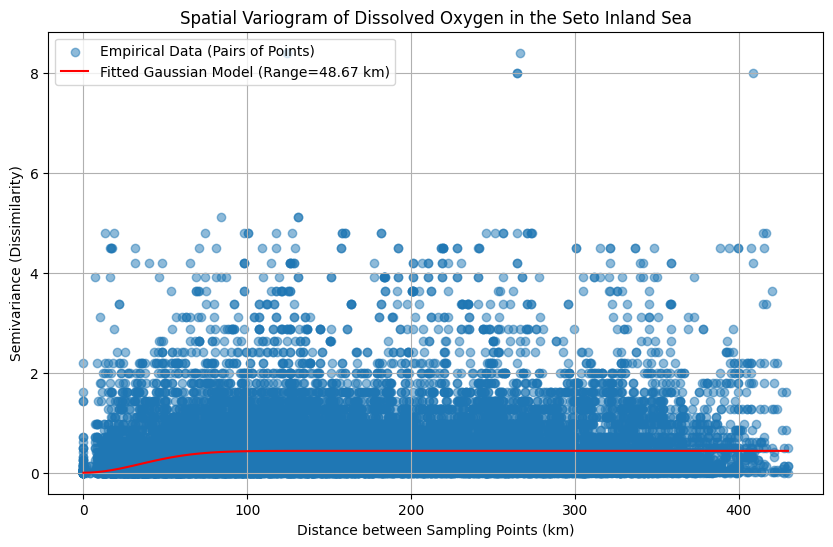

In [14]:
import matplotlib.pyplot as plt

# Generate x-values for the fitted curve
x_fit = np.linspace(0, max(distances_km), 100)
# Calculate y-values for the fitted curve
y_fit = gaussian_model(x_fit, fit_range, fit_sill)

# Create the plot
plt.figure(figsize=(10, 6))
# Plot the empirical data points (the variogram cloud)
plt.scatter(distances_km, semivariance, alpha=0.5, label='Empirical Data (Pairs of Points)')
# Plot the fitted model curve
plt.plot(x_fit, y_fit, 'r-', label=f'Fitted Gaussian Model (Range={fit_range:.2f} km)')

# Add labels and title
plt.title('Spatial Variogram of Dissolved Oxygen in the Seto Inland Sea')
plt.xlabel('Distance between Sampling Points (km)')
plt.ylabel('Semivariance (Dissimilarity)')
plt.grid(True)
plt.legend()
plt.show()